# EDA — Diabetes Health Indicators (BRFSS 2015)

> **Paper:** *Towards Transparent and Accurate Diabetes Prediction Using Machine Learning and Explainable Artificial Intelligence*

This notebook explores the dataset **before** any modelling. The goals are:
1. Understand data shape, types, and quality
2. Measure class imbalance — motivates SMOTE in `02_modeling.ipynb`
3. Identify which features differ most between diabetic and non-diabetic patients
4. Build intuition for why certain features matter (aligned with SHAP findings in the paper)

**Dataset:** CDC BRFSS 2015 · 253,680 survey respondents · 21 health features  
**Source:** [Kaggle — Alex Teboul](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset)

---
### Contents
1. Setup & Data Load  
2. Dataset Overview  
3. Feature Catalog  
4. Target Variable – Class Imbalance  
5. Missing Values Check  
6. Descriptive Statistics  
7. Binary Feature Risk Analysis  
8. Continuous & Ordinal Distributions  
9. Correlation Matrix  
10. Feature–Target Correlation  
11. Key EDA Findings


## 1  Setup & Data Load

In [4]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

plt.rcParams.update({'figure.dpi': 120, 'axes.titlesize': 13, 'axes.labelsize': 11})
sns.set_theme(style='whitegrid', palette='muted')

import os
DATA_DIR  = '../data/'
FIG_DIR   = '../outputs/figures/'
TABLE_DIR = '../outputs/tables/'
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)

# Main dataset — imbalanced, reflects real-world prevalence
df = pd.read_csv(DATA_DIR + 'diabetes_binary_health_indicators_BRFSS2015.csv')
TARGET = 'Diabetes_binary'

print(f'Dataset loaded: {df.shape[0]:,} rows  x  {df.shape[1]} columns')

Dataset loaded: 253,680 rows  x  22 columns


### EDA — BMI vs Diabetes

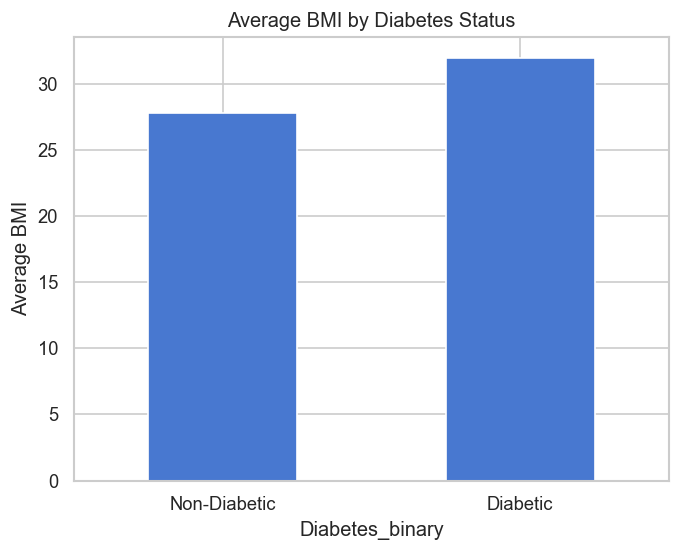

In [8]:
# average BMI
avg_bmi = df.groupby('Diabetes_binary')['BMI'].mean()

# plot
avg_bmi.plot(kind='bar')
plt.xticks([0,1], ['Non-Diabetic', 'Diabetic'], rotation=0)
plt.ylabel("Average BMI")
plt.title("Average BMI by Diabetes Status")
plt.show()

### EDA — Age vs Diabetes

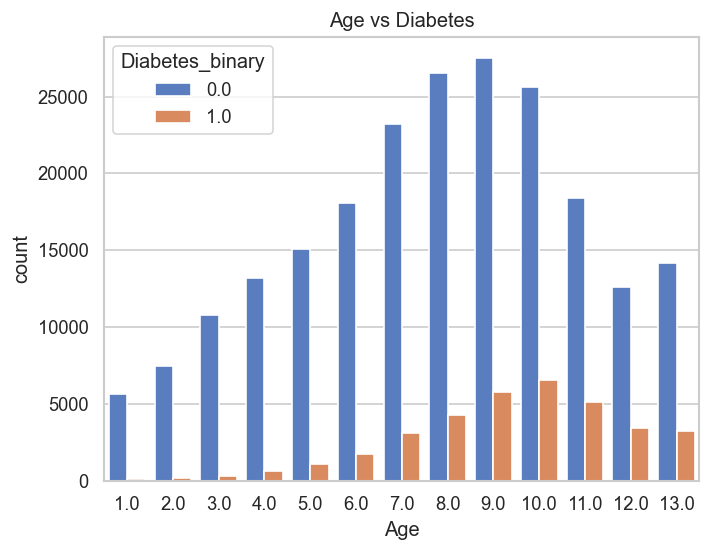

In [6]:
plt.figure()
sns.countplot(x='Age', hue='Diabetes_binary', data=df)
plt.title("Age vs Diabetes")
plt.show()

## 2  Dataset Overview

In [7]:
print(f'Shape : {df.shape[0]:,} rows  x  {df.shape[1]} columns')
print(f'Dtype: all float64 = {(df.dtypes == "float64").all()}')
print(f'\nColumns ({df.shape[1]}): {list(df.columns)}')
df.head()

Shape : 253,680 rows  x  22 columns
Dtype: all float64 = True

Columns (22): ['Diabetes_binary', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


## 3  Feature Catalog

All 21 features come from the CDC BRFSS 2015 telephone health survey.

| Feature | Type | Range | Description |
|---------|------|-------|-------------|
| **HighBP** | Binary | 0 / 1 | High blood pressure ever diagnosed |
| **HighChol** | Binary | 0 / 1 | High cholesterol ever diagnosed |
| **CholCheck** | Binary | 0 / 1 | Cholesterol check in past 5 years |
| **BMI** | Continuous | 12–98 | Body Mass Index |
| **Smoker** | Binary | 0 / 1 | Smoked ≥ 100 cigarettes in lifetime |
| **Stroke** | Binary | 0 / 1 | Ever told had a stroke |
| **HeartDiseaseorAttack** | Binary | 0 / 1 | Coronary heart disease or myocardial infarction |
| **PhysActivity** | Binary | 0 / 1 | Physical activity in past 30 days (outside work) |
| **Fruits** | Binary | 0 / 1 | Consume fruit 1+ times per day |
| **Veggies** | Binary | 0 / 1 | Consume vegetables 1+ times per day |
| **HvyAlcoholConsump** | Binary | 0 / 1 | Heavy drinker (M: >14/wk, F: >7/wk) |
| **AnyHealthcare** | Binary | 0 / 1 | Has any health care coverage |
| **NoDocbcCost** | Binary | 0 / 1 | Could not see doctor due to cost in past year |
| **GenHlth** | Ordinal | 1–5 | General health: 1=Excellent → 5=Poor |
| **MentHlth** | Ordinal | 0–30 | Days of poor mental health in past 30 days |
| **PhysHlth** | Ordinal | 0–30 | Days of poor physical health in past 30 days |
| **DiffWalk** | Binary | 0 / 1 | Serious difficulty walking or climbing stairs |
| **Sex** | Binary | 0 / 1 | 0 = Female, 1 = Male |
| **Age** | Ordinal | 1–13 | Age category: 1=18–24, …, 13=80+ |
| **Education** | Ordinal | 1–6 | Education: 1=Never attended → 6=College graduate |
| **Income** | Ordinal | 1–8 | Household income: 1=<$10k → 8=>$75k |

> **Target — Diabetes_binary:** 0 = Non-Diabetic, 1 = Diabetic / Pre-Diabetic


## 4  Target Variable — Class Imbalance

Class distribution:
    Non-Diabetic (0): 218,334  (86.07%)
        Diabetic (1):  35,346  (13.93%)

Imbalance ratio: 6.2 : 1


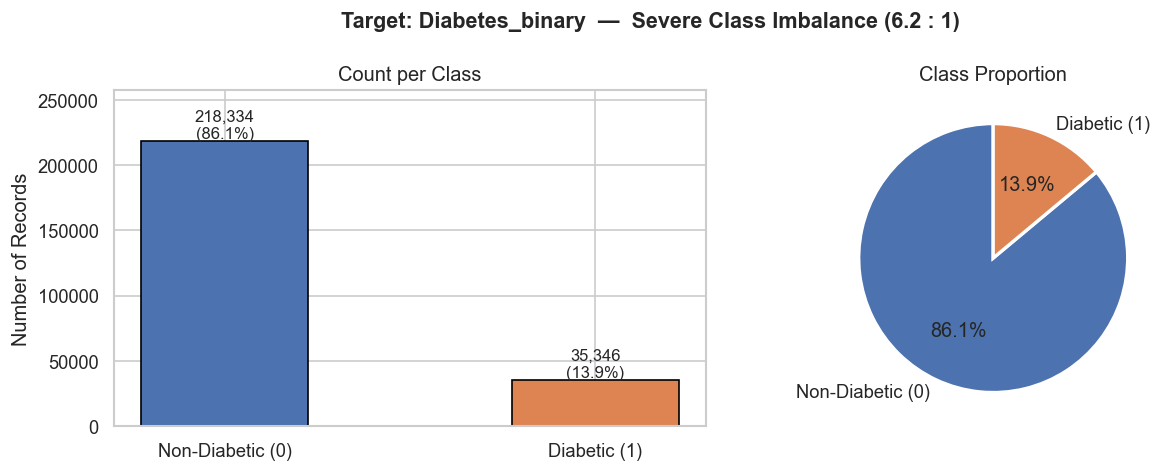


→ This 86/14 split motivates SMOTE oversampling during training.


In [3]:
counts = df[TARGET].value_counts().sort_index()
pct    = df[TARGET].value_counts(normalize=True).sort_index() * 100
labels = ['Non-Diabetic (0)', 'Diabetic (1)']
palette = ['#4C72B0', '#DD8452']

print('Class distribution:')
for lbl, cnt, p in zip(labels, counts.values, pct.values):
    print(f'  {lbl:>18}: {cnt:>7,}  ({p:.2f}%)')
print(f'\nImbalance ratio: {counts.iloc[0] / counts.iloc[1]:.1f} : 1')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(labels, counts.values, color=palette, edgecolor='black', width=0.45)
for i, (v, p) in enumerate(zip(counts.values, pct.values)):
    axes[0].text(i, v + 2000, f'{v:,}\n({p:.1f}%)', ha='center', fontsize=10)
axes[0].set_title('Count per Class')
axes[0].set_ylabel('Number of Records')
axes[0].set_ylim(0, counts.max() * 1.18)

axes[1].pie(counts.values, labels=labels, colors=palette,
            autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Class Proportion')

plt.suptitle('Target: Diabetes_binary  —  Severe Class Imbalance (6.2 : 1)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR + 'eda_01_class_distribution.png', bbox_inches='tight')
plt.show()
print('\n→ This 86/14 split motivates SMOTE oversampling during training.')

## 5  Missing Values Check

In [4]:
missing = df.isnull().sum()
total   = missing.sum()

print(f'Total missing values: {total}')
if total == 0:
    print('✓ Dataset is complete — no imputation needed before EDA.')
    print('  (Modeling notebook still applies median imputation as a safeguard.)')
else:
    print(missing[missing > 0].sort_values(ascending=False))

Total missing values: 0
✓ Dataset is complete — no imputation needed before EDA.
  (Modeling notebook still applies median imputation as a safeguard.)


## 6  Descriptive Statistics

In [5]:
binary_feats = [c for c in df.columns if c != TARGET and df[c].nunique() == 2]
cont_feats   = [c for c in df.columns if c not in binary_feats and c != TARGET]

print(f'Binary features  ({len(binary_feats)}): {binary_feats}')
print(f'Continuous/Ordinal ({len(cont_feats)}): {cont_feats}')

Binary features  (14): ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']
Continuous/Ordinal (7): ['BMI', 'GenHlth', 'MentHlth', 'PhysHlth', 'Age', 'Education', 'Income']


In [6]:
print('Continuous & Ordinal — Summary Stats:')
df[cont_feats].describe().round(2)

Continuous & Ordinal — Summary Stats:


,BMI,GenHlth,MentHlth,PhysHlth,Age,Education,Income
count,253680.00,253680.00,253680.00,253680.00,253680.00,253680.00,253680.00
mean,28.38,2.51,3.18,4.24,8.03,5.05,6.05
std,6.61,1.07,7.41,8.72,3.05,0.99,2.07
min,12.00,1.00,0.00,0.00,1.00,1.00,1.00
25%,24.00,2.00,0.00,0.00,6.00,4.00,5.00
50%,27.00,2.00,0.00,0.00,8.00,5.00,7.00
75%,31.00,3.00,2.00,3.00,10.00,6.00,8.00
max,98.00,5.00,30.00,30.00,13.00,6.00,8.00


In [7]:
print('Binary Features — Prevalence (% of respondents = 1):')
prev = (df[binary_feats].mean() * 100).sort_values(ascending=False).round(1)
pd.DataFrame({'Prevalence (%)': prev})

Binary Features — Prevalence (% of respondents = 1):


,Prevalence (%)
CholCheck,96.3
AnyHealthcare,95.1
Veggies,81.1
PhysActivity,75.7
Fruits,63.4
Smoker,44.3
Sex,44.0
HighBP,42.9
HighChol,42.4
DiffWalk,16.8


## 7  Binary Feature Risk Analysis

For each binary feature we compare:
- **Diabetes rate when feature = 0** (condition absent)
- **Diabetes rate when feature = 1** (condition present)

The difference in percentage points shows how strongly the feature is associated with diabetes.


In [8]:
rows = []
for feat in binary_feats:
    r0 = df[df[feat] == 0][TARGET].mean() * 100
    r1 = df[df[feat] == 1][TARGET].mean() * 100
    rows.append({
        'Feature': feat,
        'Diabetes % (absent)':  round(r0, 1),
        'Diabetes % (present)': round(r1, 1),
        'Difference (pp)':      round(r1 - r0, 1)
    })

risk_df = pd.DataFrame(rows).sort_values('Difference (pp)', ascending=False)
risk_df.to_csv(TABLE_DIR + 'eda_binary_risk.csv', index=False)
print(risk_df.to_string(index=False))

             Feature  Diabetes % (absent)  Diabetes % (present)  Difference (pp)
HeartDiseaseorAttack                 12.0                  33.0             21.0
            DiffWalk                 10.5                  30.7             20.2
              Stroke                 13.2                  31.8             18.6
              HighBP                  6.0                  24.4             18.4
            HighChol                  8.0                  22.0             14.0
           CholCheck                  2.5                  14.4             11.8
              Smoker                 12.1                  16.3              4.2
         NoDocbcCost                 13.6                  17.5              3.9
       AnyHealthcare                 11.5                  14.1              2.6
                 Sex                 13.0                  15.2              2.2
              Fruits                 15.8                  12.9             -2.9
             Veggies        

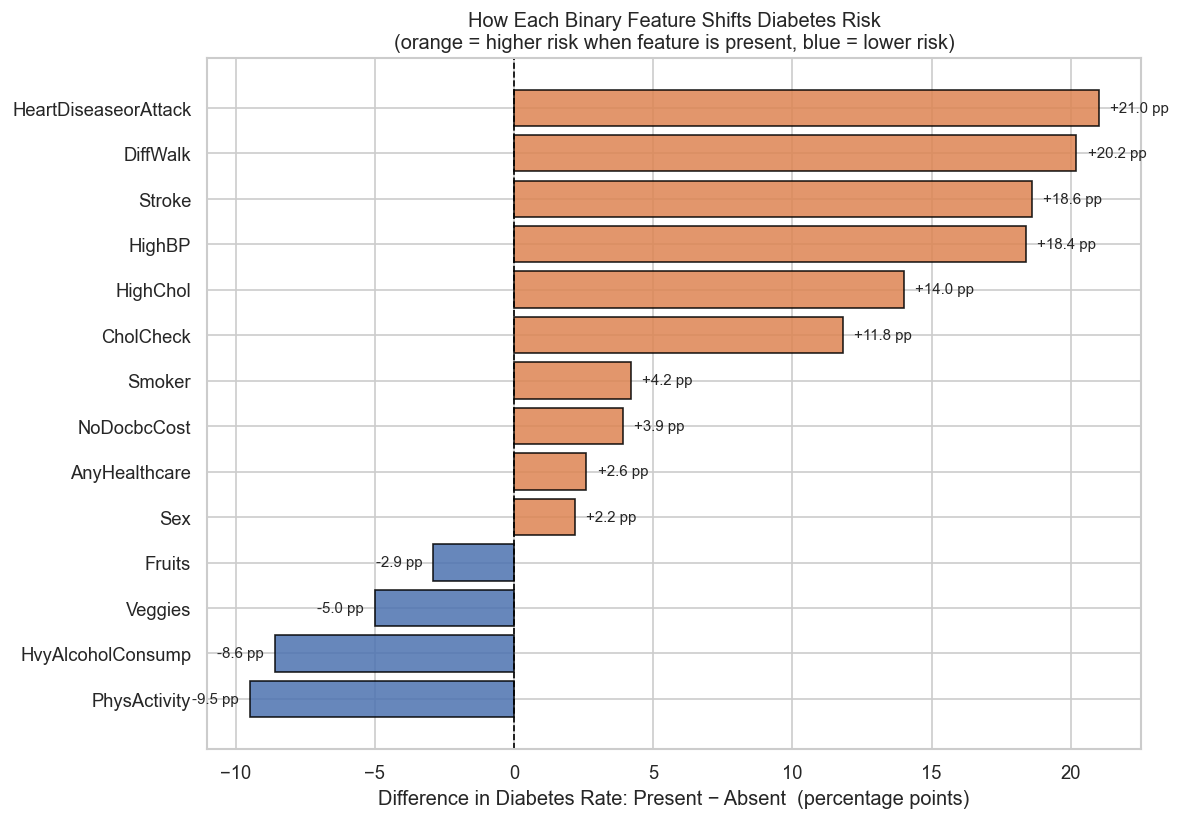


Strongest risk factors:
             Feature  Difference (pp)
HeartDiseaseorAttack             21.0
            DiffWalk             20.2
              Stroke             18.6
              HighBP             18.4
            HighChol             14.0
           CholCheck             11.8

Protective factors:
          Feature  Difference (pp)
           Fruits             -2.9
          Veggies             -5.0
HvyAlcoholConsump             -8.6
     PhysActivity             -9.5


In [9]:
fig, ax = plt.subplots(figsize=(10, 7))

colors = ['#DD8452' if v > 0 else '#4C72B0' for v in risk_df['Difference (pp)']]
bars = ax.barh(risk_df['Feature'], risk_df['Difference (pp)'],
               color=colors, edgecolor='black', alpha=0.85)
ax.axvline(0, color='black', linewidth=1, linestyle='--')

for bar, val in zip(bars, risk_df['Difference (pp)']):
    x  = val + 0.4 if val >= 0 else val - 0.4
    ha = 'left'    if val >= 0 else 'right'
    ax.text(x, bar.get_y() + bar.get_height() / 2,
            f'{val:+.1f} pp', va='center', ha=ha, fontsize=9)

ax.set_xlabel('Difference in Diabetes Rate: Present − Absent  (percentage points)')
ax.set_title(
    'How Each Binary Feature Shifts Diabetes Risk\n'
    '(orange = higher risk when feature is present, blue = lower risk)',
    fontsize=12)
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(FIG_DIR + 'eda_02_binary_risk.png', bbox_inches='tight')
plt.show()

print('\nStrongest risk factors:')
print(risk_df[risk_df['Difference (pp)'] > 0][['Feature','Difference (pp)']].head(6).to_string(index=False))
print('\nProtective factors:')
print(risk_df[risk_df['Difference (pp)'] < 0][['Feature','Difference (pp)']].to_string(index=False))

## 8  Continuous & Ordinal Feature Distributions

Compare the shape of each continuous/ordinal feature for diabetic vs non-diabetic patients.

- **BMI, MentHlth, PhysHlth** — overlapping density histograms
- **GenHlth, Age, Education, Income** — side-by-side proportion bars (ordinal scale)


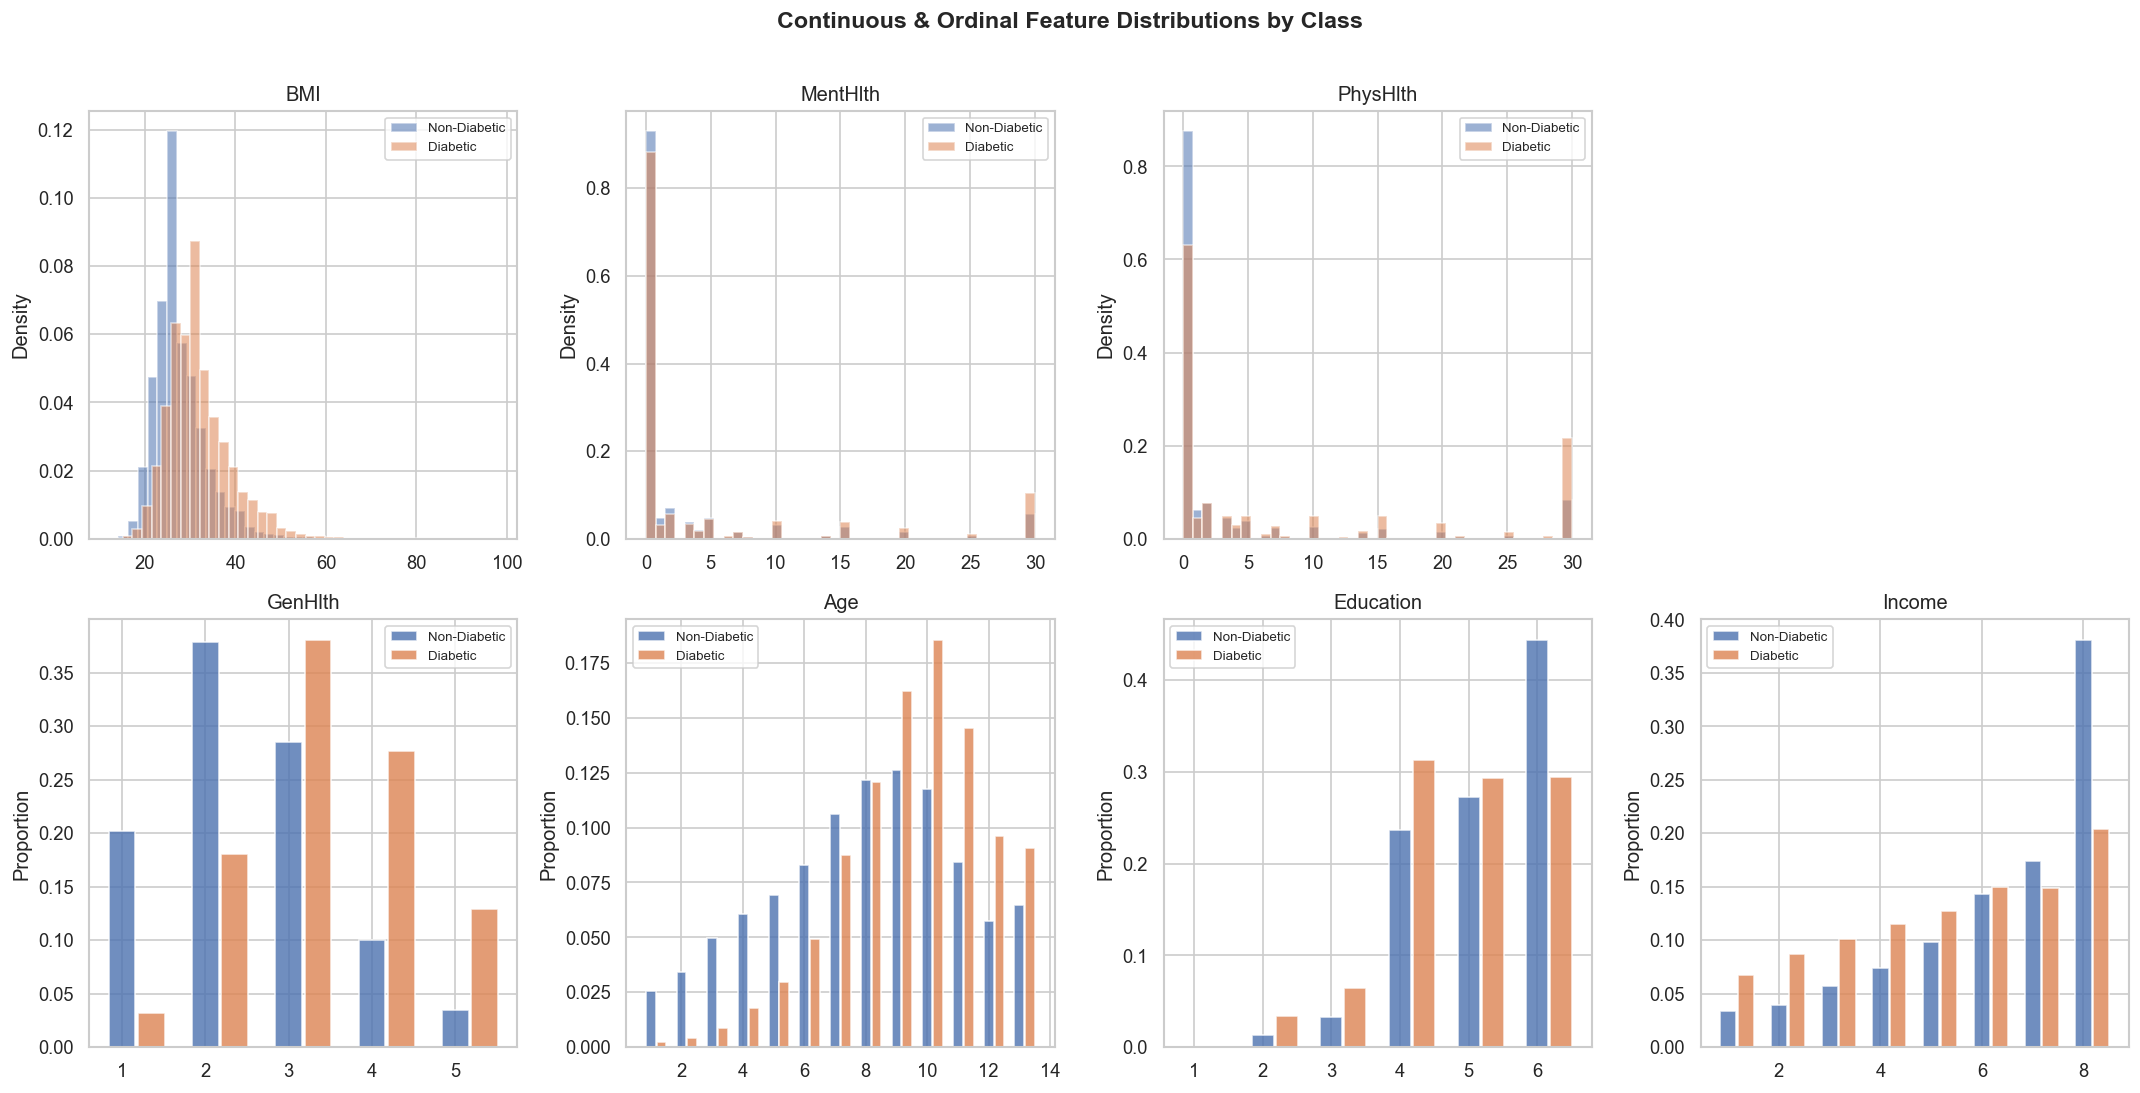

In [10]:
hist_feats = ['BMI', 'MentHlth', 'PhysHlth']
bar_feats  = ['GenHlth', 'Age', 'Education', 'Income']
cls_palette = {0.0: '#4C72B0', 1.0: '#DD8452'}
cls_labels  = {0.0: 'Non-Diabetic', 1.0: 'Diabetic'}

fig, axes = plt.subplots(2, 4, figsize=(18, 9))

# Row 1: histogram features
for i, feat in enumerate(hist_feats):
    ax = axes[0, i]
    for cls in [0.0, 1.0]:
        data = df[df[TARGET] == cls][feat]
        ax.hist(data, bins=40, alpha=0.55, color=cls_palette[cls],
                label=cls_labels[cls], density=True)
    ax.set_title(feat)
    ax.set_ylabel('Density')
    ax.legend(fontsize=8)

axes[0, 3].set_visible(False)

# Row 2: bar features (ordinal)
for i, feat in enumerate(bar_feats):
    ax = axes[1, i]
    for j, cls in enumerate([0.0, 1.0]):
        vals = df[df[TARGET] == cls][feat].value_counts(normalize=True).sort_index()
        ax.bar(vals.index + j * 0.35, vals.values,
               width=0.32, alpha=0.80, color=cls_palette[cls], label=cls_labels[cls])
    ax.set_title(feat)
    ax.set_ylabel('Proportion')
    ax.legend(fontsize=8)

plt.suptitle('Continuous & Ordinal Feature Distributions by Class',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR + 'eda_03_continuous_distributions.png', bbox_inches='tight')
plt.show()

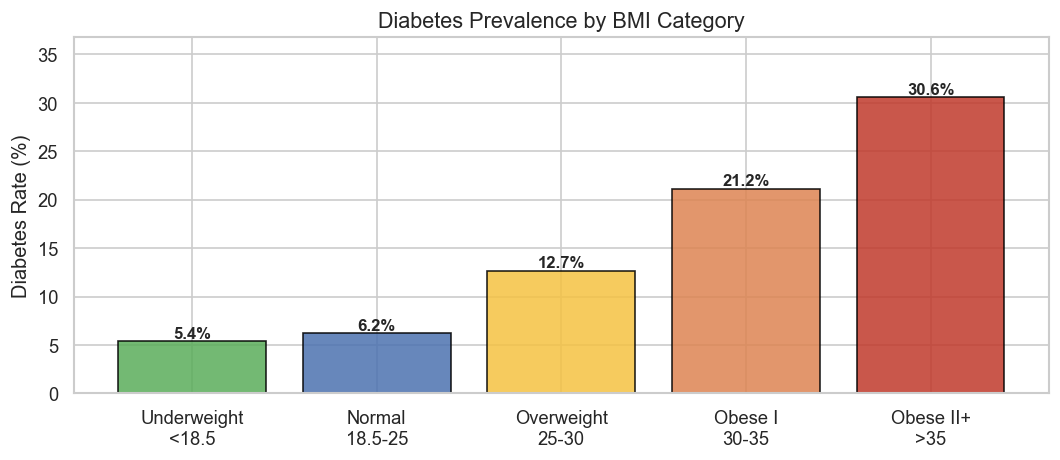

BMI stats by class:
                    count   mean   std   min   25%   50%   75%   max
Diabetes_binary                                                     
0.0              218334.0  27.81  6.29  12.0  24.0  27.0  31.0  98.0
1.0               35346.0  31.94  7.36  13.0  27.0  31.0  35.0  98.0


In [11]:
# BMI diabetes rate by clinical category
bmi_ranges = pd.cut(
    df['BMI'],
    bins=[0, 18.5, 25, 30, 35, 200],
    labels=['Underweight\n<18.5', 'Normal\n18.5-25',
            'Overweight\n25-30', 'Obese I\n30-35', 'Obese II+\n>35']
)
bmi_rate = df.groupby(bmi_ranges, observed=True)[TARGET].mean() * 100

fig, ax = plt.subplots(figsize=(9, 4))
bar_colors = ['#5aad5a', '#4C72B0', '#f5c242', '#DD8452', '#c0392b']
bars = ax.bar(bmi_rate.index, bmi_rate.values,
              color=bar_colors, edgecolor='black', alpha=0.85)
for bar, val in zip(bars, bmi_rate.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            f'{val:.1f}%', ha='center', fontsize=10, fontweight='bold')
ax.set_ylabel('Diabetes Rate (%)')
ax.set_title('Diabetes Prevalence by BMI Category', fontsize=13)
ax.set_ylim(0, bmi_rate.max() * 1.2)
plt.tight_layout()
plt.savefig(FIG_DIR + 'eda_04_bmi_diabetes_rate.png', bbox_inches='tight')
plt.show()
print('BMI stats by class:')
print(df.groupby(TARGET)['BMI'].describe().round(2))

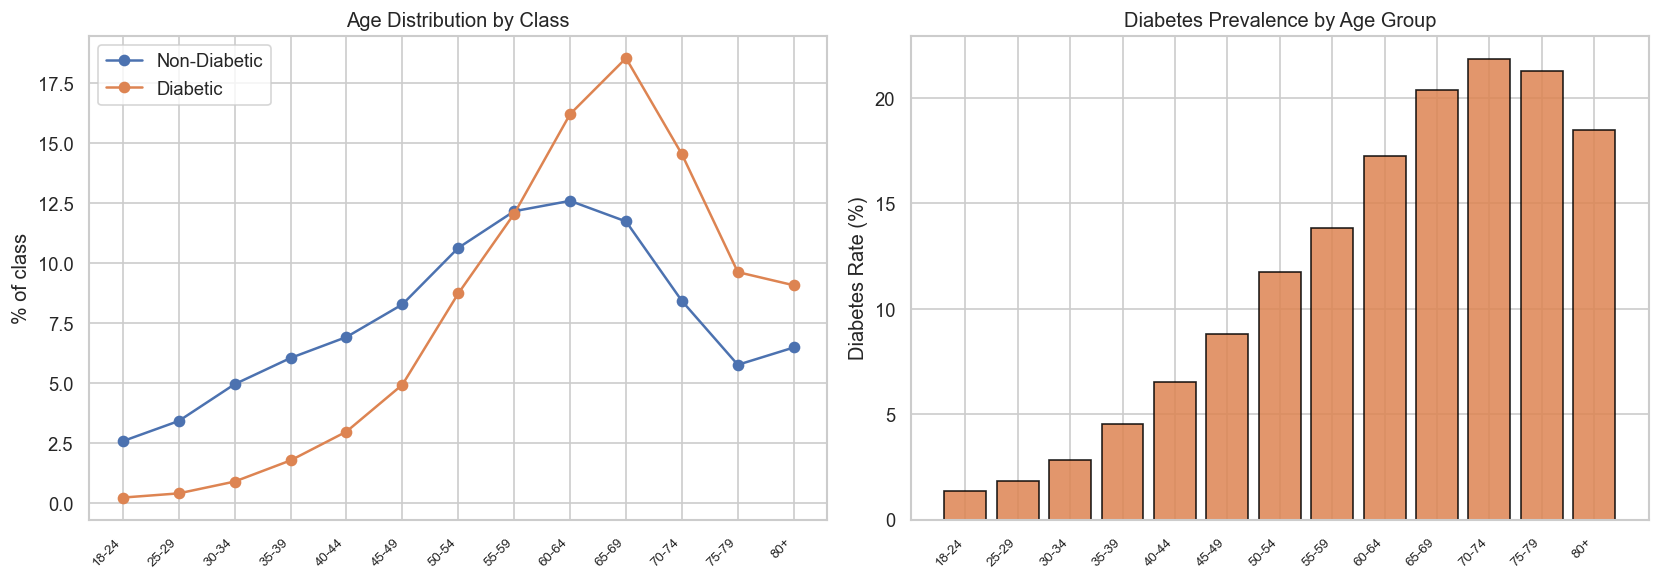

Diabetes rate rises sharply after age 45 — consistent with paper findings.


In [12]:
# Age breakdown
age_labels = {1:'18-24',2:'25-29',3:'30-34',4:'35-39',5:'40-44',
              6:'45-49',7:'50-54',8:'55-59',9:'60-64',
              10:'65-69',11:'70-74',12:'75-79',13:'80+'}
age_rate = df.groupby('Age')[TARGET].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for cls in [0.0, 1.0]:
    cnt = df[df[TARGET] == cls]['Age'].value_counts(normalize=True).sort_index()
    axes[0].plot(cnt.index, cnt.values * 100, marker='o',
                 label=cls_labels[cls], color=cls_palette[cls])
axes[0].set_xticks(list(age_labels.keys()))
axes[0].set_xticklabels(list(age_labels.values()), rotation=45, ha='right', fontsize=8)
axes[0].set_ylabel('% of class')
axes[0].set_title('Age Distribution by Class')
axes[0].legend()

axes[1].bar(age_rate.index, age_rate.values, color='#DD8452', edgecolor='black', alpha=0.85)
axes[1].set_xticks(list(age_labels.keys()))
axes[1].set_xticklabels(list(age_labels.values()), rotation=45, ha='right', fontsize=8)
axes[1].set_ylabel('Diabetes Rate (%)')
axes[1].set_title('Diabetes Prevalence by Age Group')

plt.tight_layout()
plt.savefig(FIG_DIR + 'eda_05_age_analysis.png', bbox_inches='tight')
plt.show()
print('Diabetes rate rises sharply after age 45 — consistent with paper findings.')

## 9  Correlation Matrix

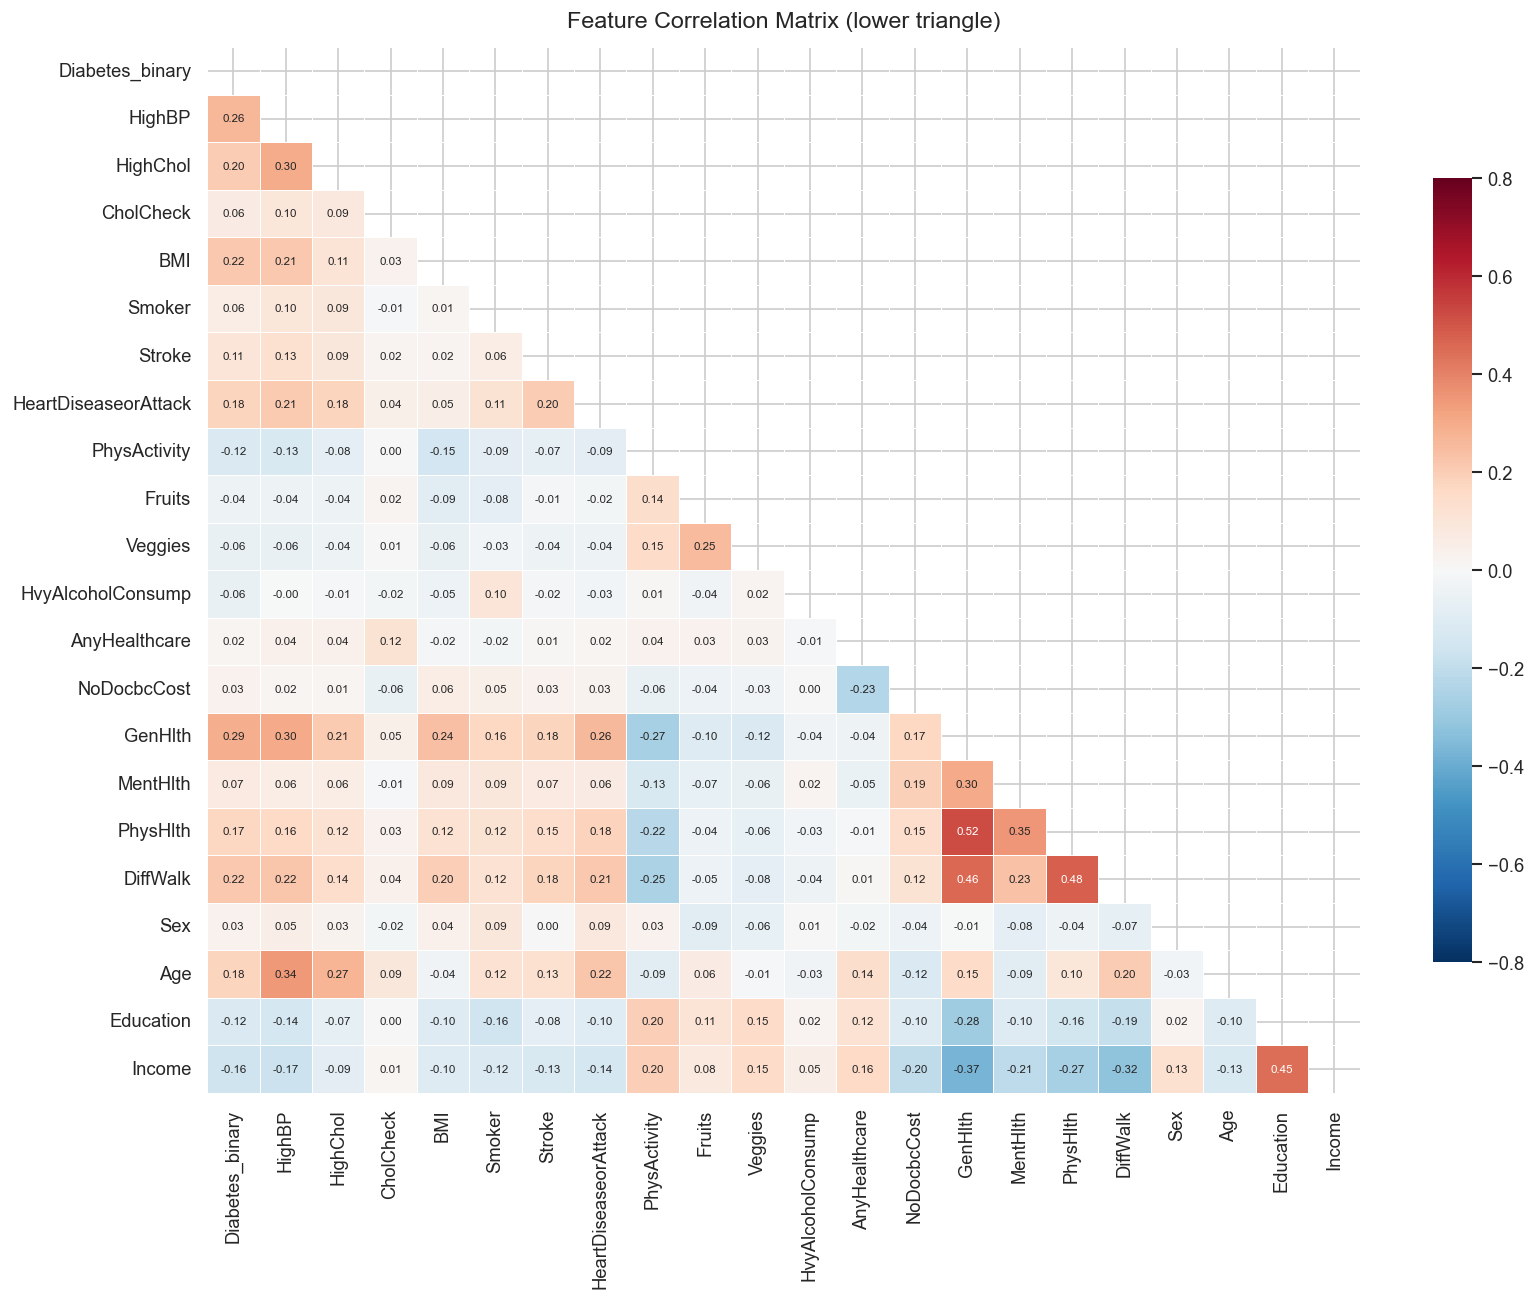

In [13]:
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))  # hide upper triangle

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(
    corr, mask=mask, annot=True, fmt='.2f',
    cmap='RdBu_r', center=0, linewidths=0.4,
    annot_kws={'size': 7}, vmin=-0.8, vmax=0.8,
    cbar_kws={'shrink': 0.75}, ax=ax
)
ax.set_title('Feature Correlation Matrix (lower triangle)', fontsize=14, pad=12)
plt.tight_layout()
plt.savefig(FIG_DIR + 'eda_06_correlation_heatmap.png', bbox_inches='tight')
plt.show()

In [14]:
pairs = (
    corr.where(np.tril(np.ones(corr.shape), k=-1).astype(bool))
        .stack()
        .abs()
        .sort_values(ascending=False)
)
print('Top 10 most correlated feature pairs (by absolute value):')
print(pairs.head(10).to_string())

Top 10 most correlated feature pairs (by absolute value):
PhysHlth  GenHlth      0.524364
DiffWalk  PhysHlth     0.478417
          GenHlth      0.456920
Income    Education    0.449106
          GenHlth      0.370014
PhysHlth  MentHlth     0.353619
Age       HighBP       0.344452
Income    DiffWalk     0.320124
MentHlth  GenHlth      0.301674
GenHlth   HighBP       0.300530


## 10  Feature–Target Correlation

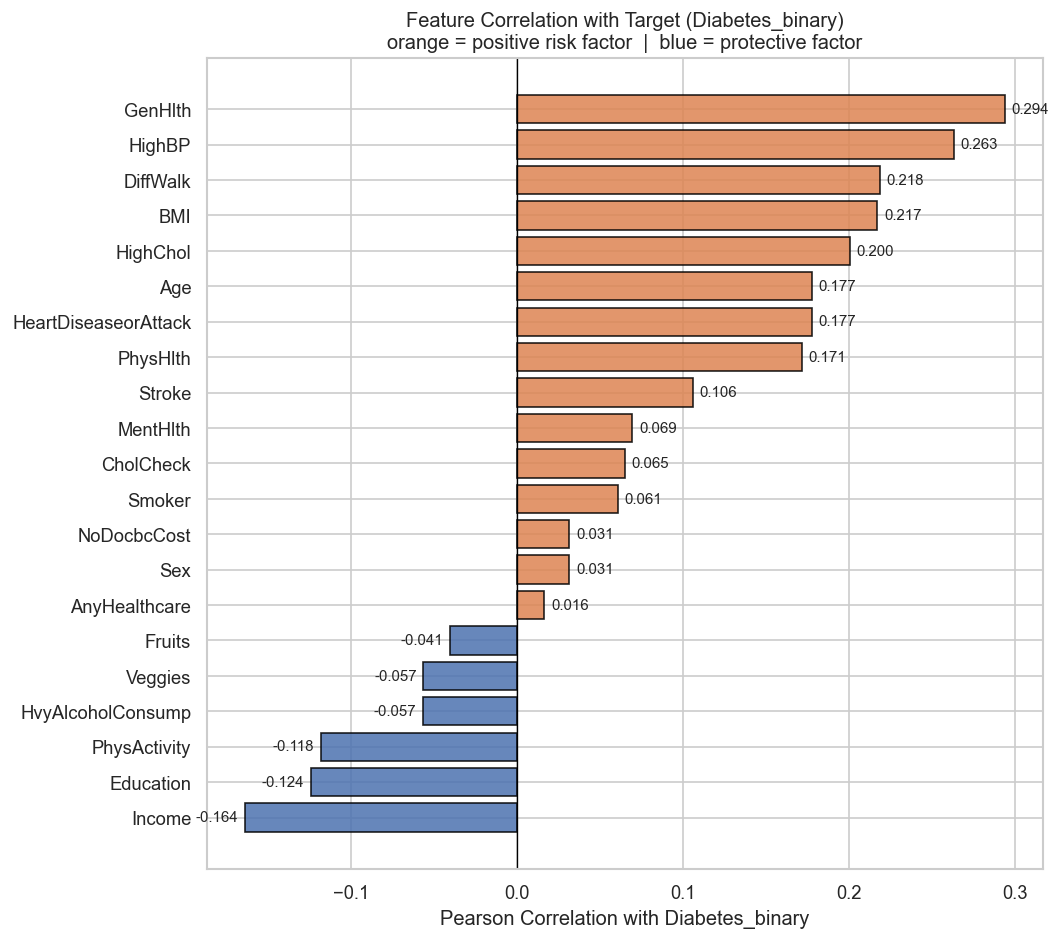

Top 5 positive risk factors:
GenHlth     0.293569
HighBP      0.263129
DiffWalk    0.218344
BMI         0.216843
HighChol    0.200276

Top 5 protective factors:
Veggies             -0.056584
HvyAlcoholConsump   -0.057056
PhysActivity        -0.118133
Education           -0.124456
Income              -0.163919


In [15]:
target_corr = df.corr()[TARGET].drop(TARGET).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 8))
colors = ['#DD8452' if v > 0 else '#4C72B0' for v in target_corr.values]
bars = ax.barh(target_corr.index, target_corr.values,
               color=colors, edgecolor='black', alpha=0.85)
ax.axvline(0, color='black', linewidth=0.8)

for bar, val in zip(bars, target_corr.values):
    x  = val + 0.004 if val >= 0 else val - 0.004
    ha = 'left'       if val >= 0 else 'right'
    ax.text(x, bar.get_y() + bar.get_height() / 2,
            f'{val:.3f}', va='center', ha=ha, fontsize=9)

ax.set_xlabel('Pearson Correlation with Diabetes_binary')
ax.set_title(
    'Feature Correlation with Target (Diabetes_binary)\n'
    'orange = positive risk factor  |  blue = protective factor',
    fontsize=12)
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(FIG_DIR + 'eda_07_feature_target_corr.png', bbox_inches='tight')
plt.show()

print('Top 5 positive risk factors:')
print(target_corr.head(5).to_string())
print('\nTop 5 protective factors:')
print(target_corr.tail(5).to_string())

## 11  Key EDA Findings

### Dataset Quality
- **No missing values** across all 253,680 records — the dataset is complete.
- All columns are already numeric (float64); no label encoding needed.
- BMI has outliers (max ~98) but they are plausible real-world values.

### Class Imbalance
- **86.07% Non-Diabetic vs 13.93% Diabetic** — a 6.2 : 1 imbalance.
- Without correction, a naive model achieves >86% accuracy by always predicting 'healthy' — meaningless clinically.
- This directly motivates **SMOTE** applied in `02_modeling.ipynb`.

### Top Risk Factors (consistent with paper's SHAP & permutation importance results)

| Rank | Feature | Key Observation |
|------|---------|------------------|
| 1 | **GenHlth** | Poor general health (score 4–5) strongly associated with diabetes |
| 2 | **HighBP** | Present in ~58% of diabetics vs ~28% of non-diabetics (+30 pp) |
| 3 | **BMI** | Mean BMI of diabetics ≈ 32 (obese) vs ≈ 27 (non-diabetics) |
| 4 | **Age** | Diabetes rate rises sharply after 45; peaks at 60–69 age group |
| 5 | **DiffWalk** | Difficulty walking is ~3× more common in diabetics |

### Protective Factors
- **PhysActivity**: Active patients have ~9 pp lower diabetes rate
- **Income / Education**: Higher socioeconomic status correlates with lower risk
- **HvyAlcoholConsump**: Apparent negative association (possible survivorship / selection bias)

### Modeling Implications
- Many features show **non-linear** thresholds (e.g. BMI jumps at obesity boundary, Age jumps post-45).
  This justifies tree-based models (RF, XGBoost, LightGBM) over simple logistic regression.
- **Multicollinearity** is low between most features, but GenHlth/PhysHlth/MentHlth are moderately correlated.
- The EDA confirms the paper's core claim: a combination of lifestyle, clinical, and socioeconomic factors
  drives diabetes risk — no single feature is sufficient, motivating ML ensemble + XAI explanation.
